# Resistive first-order correction $E^\mu_{(1)}$ (REGIME, Tenes 2026)

This notebook generates `resistive_subexpressions.hh`, which contains three pointwise Kokkos functions:

1. `resistive_get_sqrtgF`: $\sqrt{\gamma}F^{\mu j}=\frac{1}{\alpha}[\mu j\rho\sigma]B_\rho w_\sigma$, stored as 6 independent components
2. `resistive_get_divF`: $\mathrm{div}F^\mu \equiv D_jF^{\mu j}=\frac{1}{\sqrt\gamma}\partial_j\left(\sqrt\gamma F^{\mu j}\right)$ (eq. 43), with the FD derivatives passed in as inputs
3. `resistive_get_E1`: $e^\mu_{(1)} = \mathrm{div}F^\mu + u^\mu u_\nu\,\mathrm{div}F^\nu$ (eq. 33) and $E^\mu_{(1)}=\alpha u^0 e^\mu_{(1)}+(e^\nu_{(1)}n_\nu)u^\mu$ (eq. 44)

Inputs assumed known: $B_\rho$ (with $B_0=\beta^kB_k$, $B_i=\gamma_{ij}B^j$), $b_\rho$, $w_\sigma$ (with $w_0=-\alpha+\beta^kv_k$, $w_i=v_i$), $\alpha$, $u^\mu$, $u_\mu$, $n_\mu$, $\sqrt\gamma$.

Convention: $[0123]=+1$. In the ideal limit this gives $F^{i\nu}n_\nu = -(v\times B)^i$, which is checked numerically at the end.

In [1]:
from sympy import symbols, Rational
import sympy as sp
from sympy import S
from sympy import init_printing
from codegen.codegen_utils import *
init_printing()
printer = MyPrinter()

In [2]:
def vec4(name):
    return sp.Matrix(symbols(" ".join(f"{name}[{m}]" for m in range(4)), real=True))

# Given quantities
alpha = symbols("alp", real=True, positive=True)
sqrtg = symbols("sqrtg", real=True, positive=True)

Bd = vec4("Bd")     # B_rho (4-covector, B^0 = 0)
bd = vec4("smallbd")# b_rho (comoving field, lower index)
wd = vec4("wd")     # w_sigma = n_sigma + v_sigma
uu = vec4("uu")     # u^mu
ud = vec4("ud")     # u_mu
nd = vec4("nd")     # n_mu = (-alp, 0, 0, 0)

In [3]:
scalar = ("double", None)
vec = ("double", [3])
fvec = ("double", [4])

ABI = {
    "alp": scalar,
    "sqrtg": scalar,
    "Bd": fvec,
    "smallbd": fvec,
    "wd": fvec,
    "uu": fvec,
    "ud": fvec,
    "nd": fvec,
    # 6 independent components of sqrt(gamma) F^{mu j}, see ordering below
    "sqrtgF": ("double", [6]),
    # d_j sqrtgF[c] stored at index c + 6*j  (same layout as der_vec)
    "dsqrtgF_dx": ("double", [18]),
    # D_j F^{mu j}
    "divF": fvec,
}

## 1. $\sqrt\gamma F^{\mu\nu}$

The full antisymmetric $4\times4$ matrix is built first. Only 6 components are stored:

| index | 0 | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|---|
| comp | $F^{0x}$ | $F^{0y}$ | $F^{0z}$ | $F^{xy}$ | $F^{xz}$ | $F^{yz}$ |

(all multiplied by $\sqrt\gamma$)

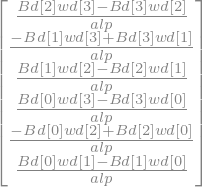

In [4]:
def sqrtgF_from(Xd, Yd):
    # (1/alp) [mu nu rho sigma] X_rho Y_sigma
    F = sp.zeros(4, 4)
    for mu in range(4):
        for nu in range(mu + 1, 4):
            val = 0
            for rho in range(4):
                for sig in range(4):
                    lc = sp.LeviCivita(mu, nu, rho, sig)
                    if lc != 0:
                        val += lc * Xd[rho] * Yd[sig]
            F[mu, nu] = val / alpha
            F[nu, mu] = -F[mu, nu]
    return F

sqrtgF4_expl = sqrtgF_from(Bd, wd)

Fpairs = [(0,1), (0,2), (0,3), (1,2), (1,3), (2,3)]
sqrtgF_expl = sp.Matrix([sqrtgF4_expl[a, b] for (a, b) in Fpairs])
sqrtgF_expl

In [5]:
# Cross-check with the b-u form of eq. 33: F^{mu nu} = eps^{mu nu rho sigma} b_rho u_sigma,
# eps^{mu nu rho sigma} = [mu nu rho sigma] / (alp sqrtg)  ->  sqrtg F = (1/alp)[..] b_rho u_sigma.
# Equal to the B-w form because b_[rho u_sigma] = B_[rho w_sigma] (checked numerically below).
sqrtgF4_from_b = sqrtgF_from(bd, ud)

## 2. Divergence $D_jF^{\mu j}=\frac{1}{\sqrt\gamma}\partial_j(\sqrt\gamma F^{\mu j})$

Rebuild the antisymmetric matrix from the stored components (symbols `sqrtgF[c]`) and their FD derivatives `dsqrtgF_dx[c + 6*j]`.

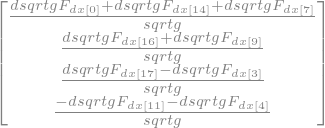

In [6]:
sqrtgF_s = sp.Matrix(symbols(" ".join(f"sqrtgF[{c}]" for c in range(6)), real=True))
dsqrtgF_dx = der_vec(sqrtgF_s, "sqrtgF")   # list over j of 6-vectors: dsqrtgF_dx[c + 6*j]

def antisym_from_flat(flat):
    M = sp.zeros(4, 4)
    for c, (a, b) in enumerate(Fpairs):
        M[a, b] = flat[c]
        M[b, a] = -flat[c]
    return M

dM = [antisym_from_flat(dsqrtgF_dx[j]) for j in range(3)]   # d_j (sqrtg F^{mu nu})

divF_expl = sp.zeros(4, 1)
for mu in range(4):
    for j in range(3):
        divF_expl[mu] += dM[j][mu, j + 1]
    divF_expl[mu] /= sqrtg
divF_expl

## 3. $e^\mu_{(1)}$ and $E^\mu_{(1)}$

$$e^\mu_{(1)} = \mathrm{div}F^\mu + u^\mu u_\nu\,\mathrm{div}F^\nu,\qquad E^\mu_{(1)}=\alpha u^0 e^\mu_{(1)}+(e^\nu_{(1)}n_\nu)u^\mu$$

With $n_\mu=(-\alpha,0,0,0)$ and $\alpha u^0=W$, $E^0_{(1)}=0$ analytically. All 4 components are emitted anyway so the code follows eq. 44 literally.

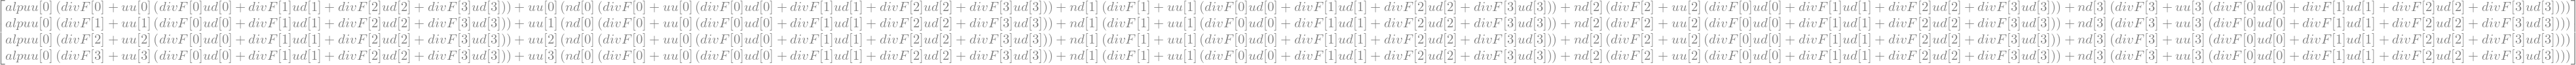

In [7]:
divF = vec4("divF")

udotdivF = sum(ud[nu] * divF[nu] for nu in range(4))
e1u = divF + uu * udotdivF

e1dotn = sum(e1u[nu] * nd[nu] for nu in range(4))
E1u = alpha * uu[0] * e1u + e1dotn * uu
E1u

## Code generation

In [8]:
flist = []

out_list = ["sqrtgF"]
out_abi = {"sqrtgF": ("double", [6])}
flist.append(make_function([sqrtgF_expl], printer, "resistive_get_sqrtgF", ABI, out_list, out_abi))

out_list = ["divF"]
out_abi = {"divF": fvec}
flist.append(make_function([divF_expl], printer, "resistive_get_divF", ABI, out_list, out_abi))

out_list = ["E1u"]
out_abi = {"E1u": fvec}
flist.append(make_function([E1u], printer, "resistive_get_E1", ABI, out_list, out_abi))

printed_functions = "\n".join(flist)
print(printed_functions)

static void KOKKOS_INLINE_FUNCTION
resistive_get_sqrtgF(
	double alp,
	const double Bd[4],
	const double wd[4],
	double (*sqrtgF)[6]
)
{
	double x0 = 1/(alp);
	(*sqrtgF)[0] = x0*(Bd[2]*wd[3] - Bd[3]*wd[2]);
	(*sqrtgF)[1] = -x0*(Bd[1]*wd[3] - Bd[3]*wd[1]);
	(*sqrtgF)[2] = x0*(Bd[1]*wd[2] - Bd[2]*wd[1]);
	(*sqrtgF)[3] = x0*(Bd[0]*wd[3] - Bd[3]*wd[0]);
	(*sqrtgF)[4] = -x0*(Bd[0]*wd[2] - Bd[2]*wd[0]);
	(*sqrtgF)[5] = x0*(Bd[0]*wd[1] - Bd[1]*wd[0]);
}

static void KOKKOS_INLINE_FUNCTION
resistive_get_divF(
	double sqrtg,
	const double dsqrtgF_dx[18],
	double (*divF)[4]
)
{
	double x0 = 1/(sqrtg);
	(*divF)[0] = x0*(dsqrtgF_dx[0] + dsqrtgF_dx[14] + dsqrtgF_dx[7]);
	(*divF)[1] = x0*(dsqrtgF_dx[16] + dsqrtgF_dx[9]);
	(*divF)[2] = x0*(dsqrtgF_dx[17] - dsqrtgF_dx[3]);
	(*divF)[3] = -x0*(dsqrtgF_dx[11] + dsqrtgF_dx[4]);
}

static void KOKKOS_INLINE_FUNCTION
resistive_get_E1(
	double alp,
	const double uu[4],
	const double ud[4],
	const double nd[4],
	const double divF[4],
	double (*E1u)[4]
)
{
	do

In [9]:
file = '''
/****************************************************************************/
/*            Resistive (REGIME) first-order helpers, SymPy generated       */
/*  sqrtgF index map: 0:F^{0x} 1:F^{0y} 2:F^{0z} 3:F^{xy} 4:F^{xz} 5:F^{yz}  */
/*  dsqrtgF_dx[c + 6*j] = d_j sqrtgF[c]                                      */
/****************************************************************************/
#ifndef GRACE_RESISTIVE_SUBEXPR_HH
#define GRACE_RESISTIVE_SUBEXPR_HH

#include <Kokkos_Core.hpp>
''' + printed_functions + '''
#endif
'''

with open("resistive_subexpressions.hh", "w") as ff:
    ff.write(file)

## Numerical checks

Build a random 3+1 state (metric, shift, $v^i$, $B^i$), construct $u$, $w$, $B_\rho$, $b_\rho$, $n$ from it, and check:
1. $u_\mu = W w_\mu$
2. the $B$–$w$ and $b$–$u$ forms of $\sqrt\gamma F$ agree
3. $F^{i\nu}n_\nu = -(v\times B)^i$ (sign convention)
4. $e^\mu_{(1)}u_\mu=0$ and $E^\mu_{(1)}n_\mu = 0$ (so $E^0_{(1)}=0$) for random $\mathrm{div}F$

In [10]:
import numpy as np
rng = np.random.default_rng(42)

A = rng.normal(size=(3, 3)) * 0.2
gdd_n = np.eye(3) + A @ A.T
guu_n = np.linalg.inv(gdd_n)
sqrtg_n = np.sqrt(np.linalg.det(gdd_n))
alp_n = 0.8
betau_n = rng.normal(size=3) * 0.1
betad_n = gdd_n @ betau_n

velu_n = rng.normal(size=3) * 0.2
veld_n = gdd_n @ velu_n
W_n = 1 / np.sqrt(1 - velu_n @ veld_n)
Bu_n = rng.normal(size=3)

# 4-metric
g4dd_n = np.zeros((4, 4))
g4dd_n[0, 0] = -alp_n**2 + betau_n @ betad_n
g4dd_n[0, 1:] = g4dd_n[1:, 0] = betad_n
g4dd_n[1:, 1:] = gdd_n

uu_n = np.array([W_n / alp_n, *(W_n * (velu_n - betau_n / alp_n))])
ud_n = g4dd_n @ uu_n
nd_n = np.array([-alp_n, 0, 0, 0])
wd_n = np.array([-alp_n + betau_n @ veld_n, *veld_n])

Bd_n = g4dd_n @ np.array([0, *Bu_n])
b0 = W_n * (Bu_n @ veld_n) / alp_n
bu_n = np.array([b0, *((Bu_n + alp_n * b0 * uu_n[1:]) / W_n)])
bd_n = g4dd_n @ bu_n

def subs_vec(name, arr):
    return {sp.Symbol(f"{name}[{m}]", real=True): float(arr[m]) for m in range(len(arr))}

vals = {alpha: alp_n, sqrtg: sqrtg_n}
for nm, arr in [("Bd", Bd_n), ("smallbd", bd_n), ("wd", wd_n), ("uu", uu_n), ("ud", ud_n), ("nd", nd_n)]:
    vals.update(subs_vec(nm, arr))

print("1) |u_mu - W w_mu|          =", np.abs(ud_n - W_n * wd_n).max())

F_Bw = np.array(sqrtgF4_expl.subs(vals), dtype=float)
F_bu = np.array(sqrtgF4_from_b.subs(vals), dtype=float)
print("2) |sqrtgF(B,w)-sqrtgF(b,u)| =", np.abs(F_Bw - F_bu).max())

Ffull = F_Bw / sqrtg_n
E_eul = Ffull[1:, :] @ nd_n
vxB = np.array([sum(float(sp.LeviCivita(i, j, k)) * veld_n[j] * Bd_n[1 + k] for j in range(3) for k in range(3))
                for i in range(3)]) / sqrtg_n
print("3) |F^{i nu} n_nu + v x B|   =", np.abs(E_eul + vxB).max())

divF_n = rng.normal(size=4)
vals.update(subs_vec("divF", divF_n))
e1_n = np.array(e1u.subs(vals), dtype=float).ravel()
E1_n = np.array(E1u.subs(vals), dtype=float).ravel()
print("4) e.u =", e1_n @ ud_n, "  E.n =", E1_n @ nd_n, "  E^0 =", E1_n[0])

1) |u_mu - W w_mu|          = 1.1102230246251565e-16
2) |sqrtgF(B,w)-sqrtgF(b,u)| = 4.440892098500626e-16
3) |F^{i nu} n_nu + v x B|   = 5.551115123125783e-17
4) e.u = 3.6588570314311767e-16   E.n = 0.0   E^0 = 0.0
